# AAA: Robin proposal vs. MD reference vs. MD-corrected samples

Three distributions, all scored with the **same** OpenMM potential (`amber14-all.xml` + `implicit/obc1.xml`, 310 K) built by `SinglePeptideDataModule.setup_potential()`, so the energies are directly comparable (units of kT):

1. **MD reference / true data** (green) — `SinglePeptideDataModule.data_test.data`, a strided 10k subsample of the ground-truth MD test split. This is the target distribution.
2. **Proposal** (red) — the unadjusted Robin samples in `robin_samples/AAA/`.
3. **MD-corrected** (blue) — the same Robin samples after energy minimisation, 50 ps equilibration and 0.5 ns of production MD, read from `robin_md_trajectories/AAA/`.

The corrected samples are always taken from **one pre-committed frame** of every trajectory: `FRAME = 1, 10, 100, 1000`. Frames are saved every 0.01 ps, so these correspond to roughly 0.01, 0.1, 1 and 10 ps of production after the 50 ps burn-in. Each frame gets its own plot below.

In [1]:
import contextlib
import glob
import os
import sys

import numpy as np
import torch
import openmm.app as app
from IPython.display import Image, display
from mdtraj.formats import DCDTrajectoryFile

from src.data.single_peptide_datamodule import SinglePeptideDataModule
from src.evaluation.plots.plot_energies import plot_energies

PEPTIDE = "AAA"

# Frames are chosen up front: the k-th saved frame of every trajectory.
FRAMES = [1, 10, 100, 1000]

N_REF = 10_000                 # size of the strided MD-reference subsample
SAMPLE_DIR = f"robin_samples/{PEPTIDE}"
TRAJ_DIR = f"robin_md_trajectories/{PEPTIDE}"
MAX_ENERGY = -100.0            # crop the pathological high-energy proposal tail

## 1. MD reference (ground truth)

Same construction as `plot_robin_energies.ipynb`: take the test split and stride it down to 10k samples.

In [2]:
dm = SinglePeptideDataModule(
    repo_id="transferable-samplers/sequential-boltzmann-generators-data",
    data_dir="data", sequence=PEPTIDE, temperature=310, num_dimensions=3, num_atoms=0,
)
dm.prepare_data()
dm.setup()
pot = dm.setup_potential()

md_ref = dm.data_test.data
md_ref = md_ref[:: max(1, len(md_ref) // N_REF)][:N_REF]
E_md_ref = pot.energy(md_ref).flatten()
print(f"MD reference: {tuple(md_ref.shape)}, E mean = {E_md_ref.mean():.2f}")

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

MD reference: (10000, 33, 3), E mean = -153.67


## 2. Unadjusted Robin proposal samples

The PDB files were written with `dm.pdb.topology`, so their atom order already matches `dm.topology`; no reindexing is needed. Coordinates are in nm.

In [3]:
sample_files = sorted(glob.glob(f"{SAMPLE_DIR}/{PEPTIDE}_*.pdb"))
proposal_positions = torch.tensor(
    np.stack([app.PDBFile(f).getPositions(asNumpy=True)._value for f in sample_files]),
    dtype=torch.float64,
)
E_proposal = pot.energy(proposal_positions).flatten()
n_out = int((E_proposal > MAX_ENERGY).sum())
print(f"Robin proposal: {tuple(proposal_positions.shape)}, "
      f"E median = {E_proposal.median():.2f}, "
      f"{n_out} samples above {MAX_ENERGY:.0f}")

Robin proposal: (9925, 33, 3), E median = -150.30, 167 samples above -100


## 3. MD-corrected samples at a fixed frame

Every `traj.dcd` is read at the same frame index. `DCDTrajectoryFile.seek` jumps straight to that frame, so the 50k-frame files are never loaded in full.

Notes:
- DCD stores coordinates in **Angstroms**; they are converted to nm so they match what `pot.energy` expects.
- The atom order of `minimized.pdb` is identical to `dm.topology`, so frames can be scored directly.
- Only the `00000 … 02927` directories are used (2927 trajectories). The stray `sampl/` directory and `00902/` (which has no `traj.dcd`) are skipped.

In [4]:
@contextlib.contextmanager
def quiet_stdout():
    """The DCD plugin prints two info lines per file on fd 1; silence them."""
    sys.stdout.flush()
    saved, devnull = os.dup(1), os.open(os.devnull, os.O_WRONLY)
    try:
        os.dup2(devnull, 1)
        yield
    finally:
        sys.stdout.flush()
        os.dup2(saved, 1)
        os.close(devnull)
        os.close(saved)


def load_frame(frame, files):
    """Positions (nm) of one DCD frame for every trajectory, in dm.topology order."""
    coords = []
    with quiet_stdout():
        for f in files:
            with DCDTrajectoryFile(f) as dcd:
                dcd.seek(frame)
                xyz, _, _ = dcd.read(1)   # Angstroms in the file
            coords.append(xyz[0] * 0.1)   # Angstrom -> nanometer
    return torch.tensor(np.stack(coords), dtype=torch.float64)


traj_files = sorted(glob.glob(f"{TRAJ_DIR}/[0-9][0-9][0-9][0-9][0-9]/traj.dcd"))
print(f"{len(traj_files)} MD trajectories found")

2927 MD trajectories found


In [5]:
E_frames = {}
for frame in FRAMES:
    x = load_frame(frame, traj_files)
    E_frames[frame] = pot.energy(x).flatten()
    print(f"frame {frame:5d}: {len(x)} samples, "
          f"E mean = {E_frames[frame].mean():.2f}, std = {E_frames[frame].std():.2f}")

frame     1: 2927 samples, E mean = -153.51, std = 6.88


frame    10: 2927 samples, E mean = -153.79, std = 7.06


frame   100: 2927 samples, E mean = -153.72, std = 7.03


frame  1000: 2927 samples, E mean = -153.59, std = 7.09


## 4. Energy plots, one per frame

`plot_energies` is called with the test energies in the "True data" slot, the unadjusted Robin energies in the "Proposal" slot, and the MD-corrected frame energies in the resampled slot (with an explicit label). The x-axis is cropped at `MAX_ENERGY = -100`; the handful of pathological, clashing proposal samples are folded into the `≥ -100` bin.

In [6]:
for frame in FRAMES:
    def save(fig, name, frame=frame):
        fig.axes[0].set_title(f"{PEPTIDE} MD-corrected, frame {frame}", fontsize=9)
        fig.savefig(f"{PEPTIDE}_energies_frame{frame:05d}.png")

    plot_energies(
        save,
        E_md_ref,
        E_proposal,
        E_frames[frame],
        None,
        max_energy=MAX_ENERGY,
        prefix="",
        resampled_label=f"MD-corrected (frame {frame})",
    )
    print(f"saved {PEPTIDE}_energies_frame{frame:05d}.png")

saved AAA_energies_frame00001.png


saved AAA_energies_frame00010.png


saved AAA_energies_frame00100.png


saved AAA_energies_frame01000.png


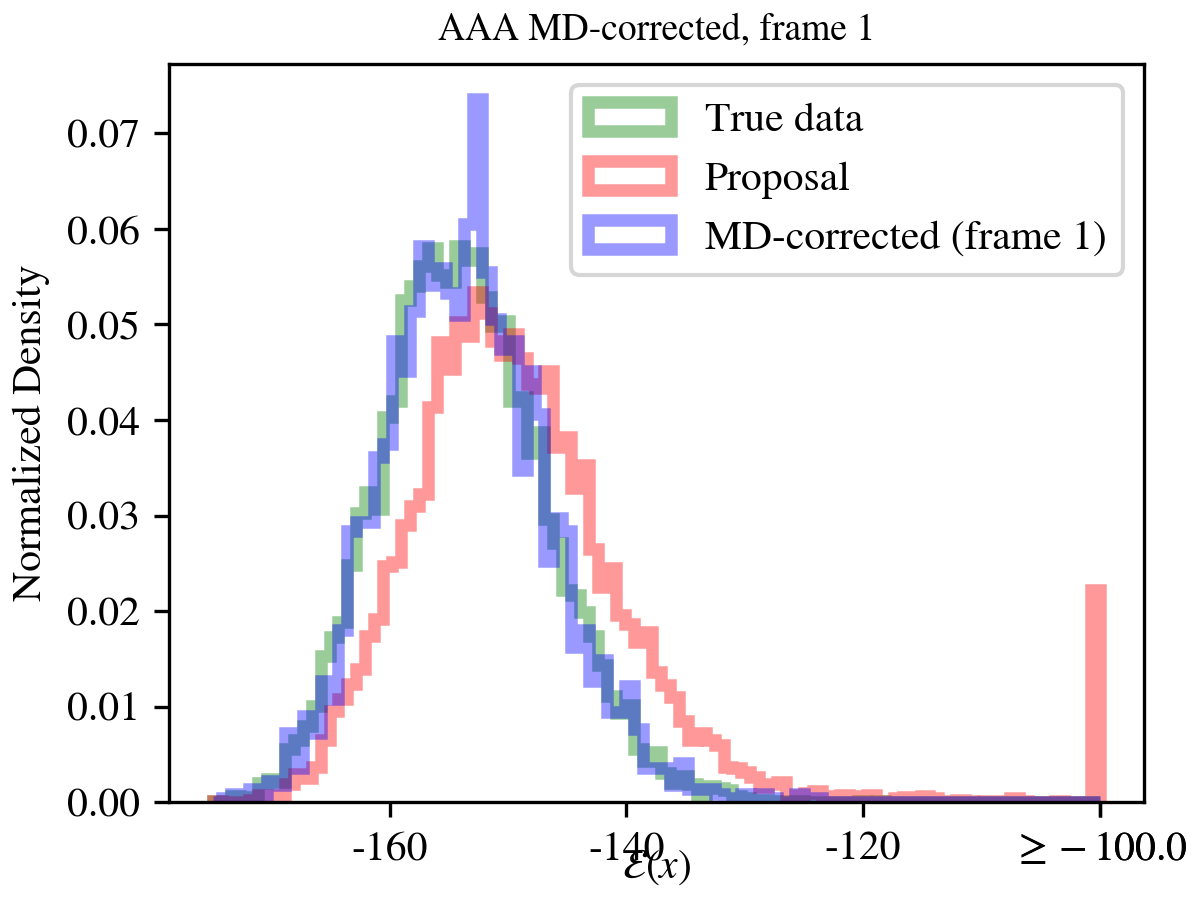

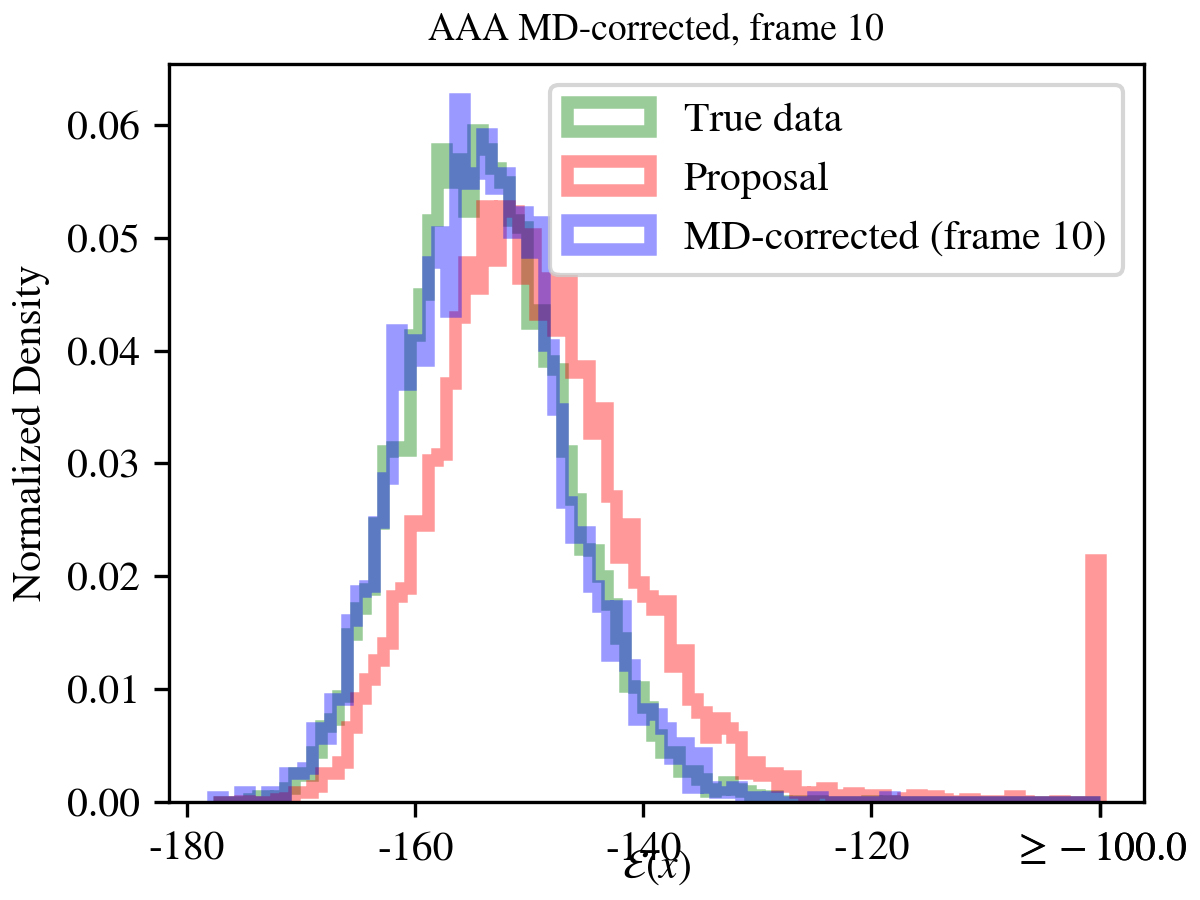

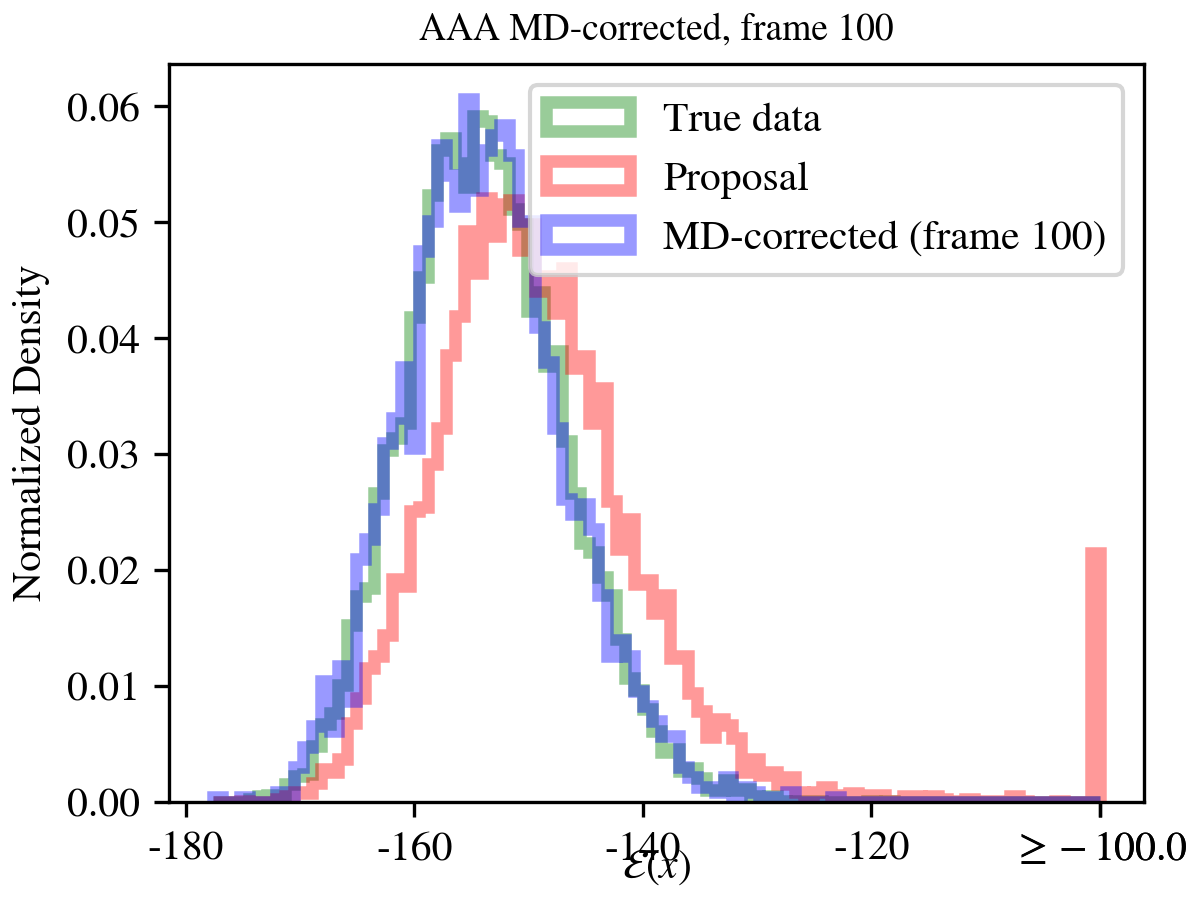

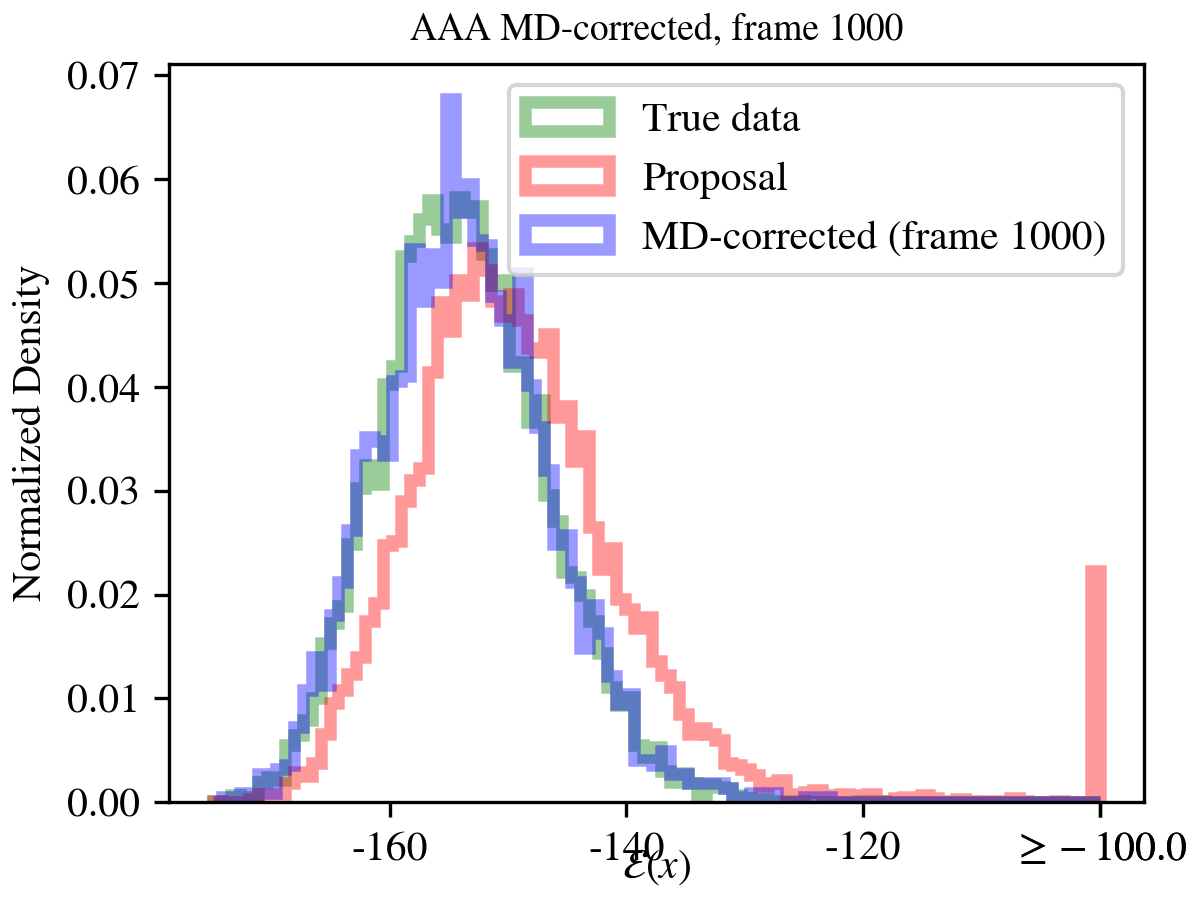

In [7]:
for frame in FRAMES:
    display(Image(f"{PEPTIDE}_energies_frame{frame:05d}.png"))

## 5. Summary statistics

Moments marked `*` are computed after clipping energies at `MAX_ENERGY = -100` (the same crop the plots use), so the pathological proposal outliers do not dominate them. `max` is the raw maximum.

In [8]:
rows = [("MD reference (test)", E_md_ref), ("Robin proposal", E_proposal)]
rows += [(f"MD-corrected (frame {f})", E_frames[f]) for f in FRAMES]

print(f"{'distribution':26s}{'n':>7s}{'> -100':>8s}{'mean*':>9s}{'std*':>8s}{'median*':>10s}{'max':>13s}")
for name, e in rows:
    e = e.double()
    clipped = torch.clamp(e, max=MAX_ENERGY)
    print(f"{name:26s}{e.numel():7d}{int((e > MAX_ENERGY).sum()):8d}"
          f"{clipped.mean():9.2f}{clipped.std():8.2f}{clipped.median():10.2f}"
          f"{float(e.max()):13.2e}")

distribution                    n  > -100    mean*    std*   median*          max
MD reference (test)         10000       0  -153.67    6.93   -153.98    -1.18e+02
Robin proposal               9925     167  -148.94   10.39   -150.30     4.96e+15
MD-corrected (frame 1)       2927       0  -153.51    6.88   -153.62    -1.24e+02
MD-corrected (frame 10)      2927       0  -153.79    7.06   -154.00    -1.18e+02
MD-corrected (frame 100)     2927       0  -153.72    7.03   -153.92    -1.23e+02
MD-corrected (frame 1000)    2927       0  -153.59    7.09   -153.86    -1.23e+02


## 6. Caveats

- The 50 ps burn-in is discarded before production starts, so all four frames are already close to stationarity; differences between frames are small and mostly visible in the tails.
- The MD-corrected set has 2927 members vs 9925 proposal / 10k reference members. The histograms are density-normalised, so this does not bias the comparison.
- Energies are translation- and rotation-invariant, so no alignment between the three sets is needed.